<a href="https://colab.research.google.com/github/Vincent-L0/L02-hedonic-pricing/blob/main/notebook_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Vincent Lam, Tiffany Kim, Ashley Hughes

**Date:** 11/11/2026

In [22]:
# Your Phase 1 solution to the problem goes here.


df.shape:
(16814, 19) 

df.dtypes:
sale_date                      object
sale_price                      int64
house_square_feet               int64
attic_finished_square_feet      int64
basement_square_feet            int64
attached_garage_square_feet     int64
detached_garage_square_feet     int64
fireplaces                      int64
hvac_description               object
exterior                       object
interior                       object
stories                         int64
roof_cover                     object
year_built                      int64
bedrooms                        int64
bathrooms                       int64
waterfront_type                object
view_quality                   object
utility_sewer                  object
dtype: object 



,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms
count,1.681400e+04,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000
mean,4.612332e+05,1879.941953,24.945878,167.852861,364.425122,38.298501,0.889021,1.558285,1980.469252,3.277983,2.317176
std,2.360833e+05,760.419008,102.066417,429.065832,286.454018,164.691471,0.596731,0.512055,33.339025,0.891240,0.827956
min,2.000000e+03,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1880.000000,0.000000,0.000000
25%,3.480000e+05,1320.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1959.000000,3.000000,2.000000
50%,4.165000e+05,1774.000000,0.000000,0.000000,420.000000,0.000000,1.000000,2.000000,1990.000000,3.000000,2.000000
75%,5.238065e+05,2352.000000,0.000000,0.000000,528.000000,0.000000,1.000000,2.000000,2006.000000,4.000000,3.000000
max,6.130000e+06,9510.000000,1212.000000,4000.000000,2816.000000,3664.000000,5.000000,3.000000,2021.000000,25.000000,8.000000


sale_date                          0
sale_price                         0
house_square_feet                  0
attic_finished_square_feet         0
basement_square_feet               0
attached_garage_square_feet        0
detached_garage_square_feet        0
fireplaces                         0
hvac_description                   7
exterior                           1
interior                           7
stories                            0
roof_cover                         8
year_built                         0
bedrooms                           0
bathrooms                          0
waterfront_type                16261
view_quality                   15895
utility_sewer                      0
dtype: int64 

hvac_description
Forced Air                10382
Electric Baseboard         2668
Heat Pump                  2084
Warm and Cool Air Zone     1268
Floor/Wall Furnace          174
Hot Water Baseboard         146
No Heat                      82
NaN                           7
Electric 

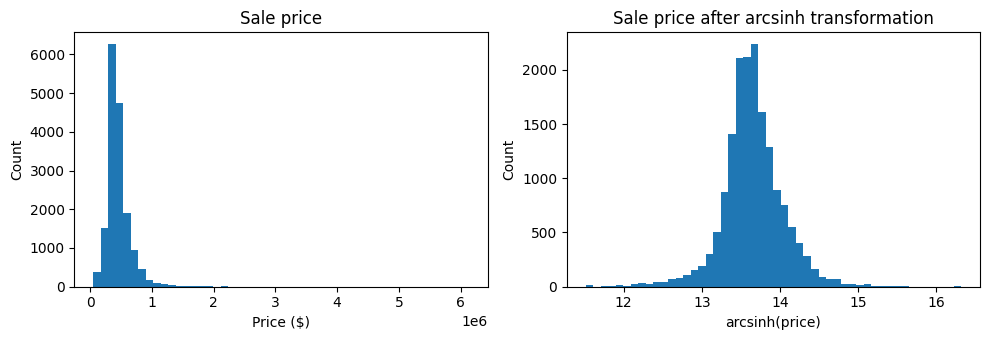

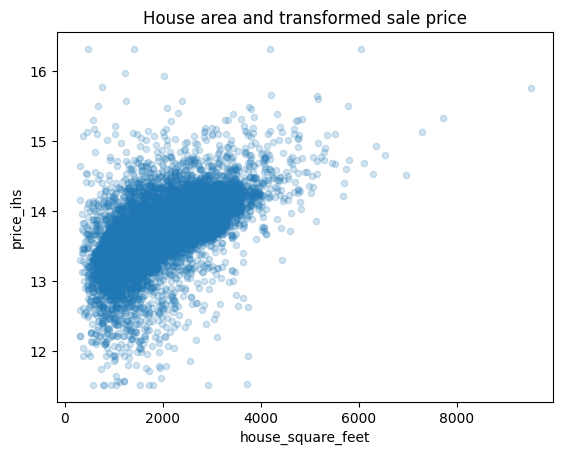

,price_ihs
price_ihs,1.000
house_square_feet,0.606
bathrooms,0.511
attached_garage_square_feet,0.391
fireplaces,0.384
year_built,0.334
bedrooms,0.312
stories,0.252
basement_square_feet,0.250
detached_garage_square_feet,0.027


In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score
from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("pierce_county_house_sales.csv")

#1 Clean the data pierce_county_house_sales.csv and perform some EDA and visualization to get to know the data set.
# Look at initial characteristics
print("df.shape:")
print(df.shape, '\n')
print("df.dtypes:")
print(df.dtypes, '\n')
display(df.describe())
print(df.isnull().sum(), '\n')

# Look at the categorical variables
for var in ["hvac_description", "exterior", "interior", "roof_cover", "waterfront_type", "view_quality", "utility_sewer"]:
    print(df[var].value_counts(dropna=False), '\n')

# Clean the data
df = df.drop_duplicates()
df["waterfront_type"] = df["waterfront_type"].fillna("None")
df["view_quality"] = df["view_quality"].fillna("None")
df["hvac_description"] = df["hvac_description"].replace("Floor Wall Furnace", "Floor/Wall Furnace")
df = df.drop(columns=["interior", "utility_sewer", "sale_date"])
df = df.dropna(subset=["hvac_description", "exterior", "roof_cover"])

# transform price
df["price_ihs"] = np.arcsinh(df["sale_price"])

# Trim recording errors and non-market sales
df = df.loc[(df["price_ihs"] > 11.5) & (df["house_square_feet"] >= 300) & (df["bedrooms"] <= 10)].copy()
print(df.shape)

# Plot price before and after the arcsinh transformation
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
df["sale_price"].hist(bins=50, grid=False, ax=axes[0])
axes[0].set(title="Sale price", xlabel="Price ($)", ylabel="Count")
df["price_ihs"].hist(bins=50, grid=False, ax=axes[1])
axes[1].set(title="Sale price after arcsinh transformation", xlabel="arcsinh(price)", ylabel="Count")
plt.tight_layout()
plt.show()

# Plot house area against transformed price
df.plot.scatter(x="house_square_feet", y="price_ihs", alpha=0.2)
plt.title("House area and transformed sale price")
plt.show()

# Correlate numeric variables with transformed price
numeric_vars = ["house_square_feet", "attic_finished_square_feet", "basement_square_feet", "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces", "stories", "bedrooms", "bathrooms", "year_built"]
correlations = df[numeric_vars + ["price_ihs"]].corr()
correlations["price_ihs"].sort_values(ascending=False).round(3)

In [24]:
#2 Transform your variables - particularly categorical ones - for use in your regression analysis.

categorical_vars = ["hvac_description", "exterior", "roof_cover", "waterfront_type", "view_quality"]
dummies = pd.get_dummies(df[categorical_vars], drop_first=True, dtype=int)
dummies.columns.tolist()

# Combine numeric variables and dummies into X, with transformed price as y
X = pd.concat([df[numeric_vars], dummies], axis=1)
y = df["price_ihs"]

In [25]:
#3 Implement an 80/20 train-test split. Put the test data aside.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=55
)

In [26]:
# 4 Build some simple linear models that include no transformations or interactions.
# Fit them, and determine their RMSE and R2 on the both the training and test sets. Which of your models does the best?
model_sets = {
    "House area only": ["house_square_feet"],
    "Numeric features": ["house_square_feet", "attic_finished_square_feet", "basement_square_feet", "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces", "stories", "bedrooms", "bathrooms", "year_built"],
    "All features": X_train.columns.tolist(),
}

for name, features in model_sets.items():
    sk_fit = LinearRegression().fit(X_train[features], y_train)

    train_prediction = sk_fit.predict(X_train[features])
    test_prediction = sk_fit.predict(X_test[features])

    print(name)
    print("Training R-squared:", round(sk_fit.score(X_train[features], y_train), 3))
    print("Test R-squared:", round(sk_fit.score(X_test[features], y_test), 3))
    print("Training RMSE:", round(root_mean_squared_error(y_train, train_prediction), 3))
    print("Test RMSE:", round(root_mean_squared_error(y_test, test_prediction), 3))
    print("-------------------")
print("The model with all features does best, with the highest test R-squared (0.524) and the lowest test RMSE (0.275).")
print("Every increase in features helpedh. House area alone had a test R-squared of 0.370, but adding the other numeric features raised it to 0.464. Adding the categorical dummies on top raised it to 0.524.")
print("The training and test numbers are close for every model, so none are overfitting.")

House area only
Training R-squared: 0.367
Test R-squared: 0.37
Training RMSE: 0.322
Test RMSE: 0.316
-------------------
Numeric features
Training R-squared: 0.469
Test R-squared: 0.464
Training RMSE: 0.295
Test RMSE: 0.292
-------------------
All features
Training R-squared: 0.533
Test R-squared: 0.524
Training RMSE: 0.276
Test RMSE: 0.275
-------------------
The model with all features does best, with the highest test R-squared (0.524) and the lowest test RMSE (0.275).
Every increase in features helpedh. House area alone had a test R-squared of 0.370, but adding the other numeric features raised it to 0.464. Adding the categorical dummies on top raised it to 0.524.
The training and test numbers are close for every model, so none are overfitting.


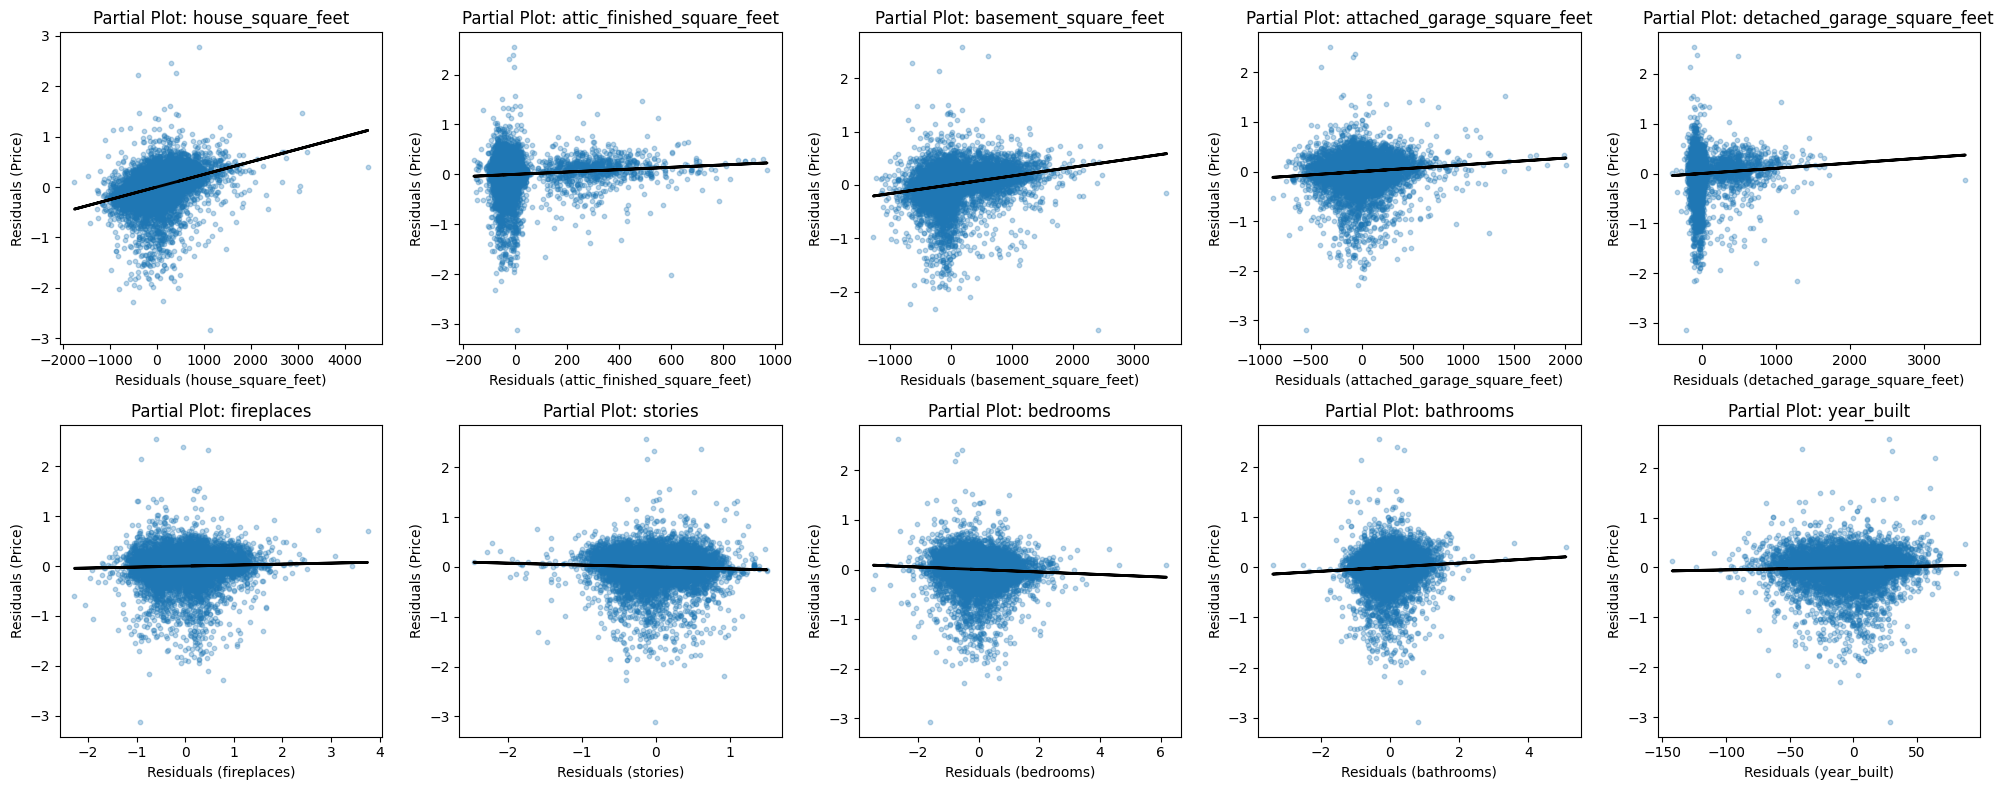

House area is the main non-linearity: for the biggest houses, each extra square foot adds less to the price.
Attic and detached garage area are zero for most houses, so a straight line doesn't fit them well.
Bedrooms has a negative effect once size is held fixed, because more bedrooms in the same space means smaller rooms.
The other variables look roughly linear, so house size is the main thing to fix in the complex model.


In [27]:
#5 Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
def slr(x, y):
    """Fit an intercept and one slope by ordinary least squares."""
    x_bar, y_bar = np.mean(x), np.mean(y)
    b1 = np.inner(x - x_bar, y - y_bar) / np.inner(x - x_bar, x - x_bar)
    b0 = y_bar - b1 * x_bar
    y_hat = b0 + b1 * x
    return {"b0": b0, "b1": b1, "y_hat": y_hat, "residuals": y - y_hat}

numeric_features = ["house_square_feet", "attic_finished_square_feet", "basement_square_feet", "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces", "stories", "bedrooms", "bathrooms", "year_built"]

fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(20, 8))
axes = axes.flatten()

for i, feature in enumerate(numeric_features):
    others = X_train.drop(columns=feature)
    r_price = y_train - LinearRegression().fit(others, y_train).predict(others)
    r_feature = X_train[feature] - LinearRegression().fit(others, X_train[feature]).predict(others)
    partial_fit = slr(r_feature, r_price)

    ax = axes[i]
    ax.scatter(r_feature, r_price, alpha=0.3, s=10)
    ax.plot(r_feature, partial_fit["y_hat"], color="black", linewidth=2)
    ax.set_title(f"Partial Plot: {feature}")
    ax.set_xlabel(f"Residuals ({feature})")
    ax.set_ylabel("Residuals (Price)")

plt.tight_layout()
plt.show()

print("House area is the main non-linearity: for the biggest houses, each extra square foot adds less to the price.")
print("Attic and detached garage area are zero for most houses, so a straight line doesn't fit them well.")
print("Bedrooms has a negative effect once size is held fixed, because more bedrooms in the same space means smaller rooms.")
print("The other variables look roughly linear, so house size is the main thing to fix in the complex model.")

In [28]:
#6 Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value.
# Determine its RMSE and R2 on the training and test sets. How does the more complex model your build compare to the simpler ones?

# Log-transform house size
X_train_log = X_train.copy()
X_test_log = X_test.copy()
X_train_log["house_square_feet"] = np.log(X_train_log["house_square_feet"])
X_test_log["house_square_feet"] = np.log(X_test_log["house_square_feet"])

# Add squares and interactions of the numeric features
numeric_features = ["house_square_feet", "attic_finished_square_feet", "basement_square_feet", "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces", "stories", "bedrooms", "bathrooms", "year_built"]
expander = make_pipeline(
    MinMaxScaler(feature_range=(-1, 1)),
    PolynomialFeatures(degree=2, include_bias=False)
)
poly_train = pd.DataFrame(expander.fit_transform(X_train_log[numeric_features]), columns=expander.get_feature_names_out(), index=X_train_log.index)
poly_test = pd.DataFrame(expander.transform(X_test_log[numeric_features]), columns=expander.get_feature_names_out(), index=X_test_log.index)

# Combine with the dummies and fit the complex model
X_train_c = pd.concat([poly_train, X_train_log.drop(columns=numeric_features)], axis=1)
X_test_c = pd.concat([poly_test, X_test_log.drop(columns=numeric_features)], axis=1)
c_model = LinearRegression().fit(X_train_c, y_train)

print("Complex Training R-squared:", round(c_model.score(X_train_c, y_train), 3))
print("Complex Test R-squared:", round(c_model.score(X_test_c, y_test), 3))
print("Complex Training RMSE:", round(root_mean_squared_error(y_train, c_model.predict(X_train_c)), 3))
print("Complex Test RMSE:", round(root_mean_squared_error(y_test, c_model.predict(X_test_c)), 3))
print("")
print("We log-transformed house area because bigger houses add less value per square foot. We also added squares so effects can curve, and interactions so one feature can change another's effect (like a bathroom adding more value in a bigger house).")
print("The complex model beats every simple model on the test set: test R-squared 0.543 vs 0.524, and test RMSE 0.269 vs 0.275.")
print("Its training and test scores are close (0.554 vs 0.543), so it isn't overfitting.")

Complex Training R-squared: 0.554
Complex Test R-squared: 0.543
Complex Training RMSE: 0.27
Complex Test RMSE: 0.269

We log-transformed house area because bigger houses add less value per square foot. We also added squares so effects can curve, and interactions so one feature can change another's effect (like a bathroom adding more value in a bigger house).
The complex model beats every simple model on the test set: test R-squared 0.543 vs 0.524, and test RMSE 0.269 vs 0.275.
Its training and test scores are close (0.554 vs 0.543), so it isn't overfitting.


In [29]:
# 7 Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
print("After cleaning (removing duplicates, filling missing waterfront and view values, dropping near-constant columns, and trimming non-market sales), we transformed sale price with arcsinh, encoded the categorical variables as dummies, and used an 80/20 train-test split.")
print("For the simple model with only house area, our training R^2 was 0.367, our test R^2 was 0.370, our training RMSE was 0.322, and our test RMSE was 0.316.")
print("For the simple model with all features and no transformations, our training R^2 was 0.533, our test R^2 was 0.524, our training RMSE was 0.276, and our test RMSE was 0.275.")
print("For the complex model with a log transformation of house area and squares and interactions of the numeric features, our training R^2 was 0.554, our test R^2 was 0.543, our training RMSE was 0.270, and our test RMSE was 0.269.")

print("RMSE is on the arcsinh price scale, so an RMSE of about 0.27 means our predictions are typically off by roughly 27% of the sale price.")
print("The house area model underfits: it is too simple to capture what drives price, so its training and test errors are both high. Adding the other numeric features and the categorical dummies lowered the error on both sets.")
print("The all-features simple model explains roughly 52% of the variation in price on unseen data. There is a relatively small gap between the training and test metrics, which indicates that the model is not overfitting.")
print("The complex model did better than every simple model on the test set, and its training and test metrics stayed close, so the extra terms captured real patterns instead of noise.")
print("We utilized transformations because sale_price and house_square_feet were both heavily right skewed, and the partial correlation plots showed diminishing returns to house size, so we transformed them to prevent outliers from dominating the regression.")
print("We learned that test metrics are very important when determining if a model is overfitting. Training error always goes down as we add features, so only the test set shows whether a model is actually learning or just memorizing the training data.")
print("We also learned that the goal of model selection is finding a good in-between. We needed a model that was complex enough to capture the patterns, like diminishing returns to house size, but we limited the squares and interactions to the numeric features instead of every column to avoid overfitting.")

After cleaning (removing duplicates, filling missing waterfront and view values, dropping near-constant columns, and trimming non-market sales), we transformed sale price with arcsinh, encoded the categorical variables as dummies, and used an 80/20 train-test split.
For the simple model with only house area, our training R^2 was 0.367, our test R^2 was 0.370, our training RMSE was 0.322, and our test RMSE was 0.316.
For the simple model with all features and no transformations, our training R^2 was 0.533, our test R^2 was 0.524, our training RMSE was 0.276, and our test RMSE was 0.275.
For the complex model with a log transformation of house area and squares and interactions of the numeric features, our training R^2 was 0.554, our test R^2 was 0.543, our training RMSE was 0.270, and our test RMSE was 0.269.
RMSE is on the arcsinh price scale, so an RMSE of about 0.27 means our predictions are typically off by roughly 27% of the sale price.
The house area model underfits: it is too simp

In [30]:
#8 Use the sklearn.linear_model.Lasso to regularize your model and select the most predictive features.
# Which does it select? What are the RMSE and R2?

# Standardize the complex-model features then fit the lasso
model = make_pipeline(StandardScaler(), Lasso(max_iter=20000))

# Choose the penalty by 5-fold cross-validation on the training data
cv = KFold(n_splits=5, shuffle=True, random_state=3001)
search = GridSearchCV(model, {"lasso__alpha": [0.0003, 0.001, 0.003, 0.01]}, cv=cv, scoring="neg_root_mean_squared_error", error_score="raise")
search.fit(X_train_c, y_train);
print("Selected alpha:", search.best_params_["lasso__alpha"])
print("Validation RMSE:", round(-search.best_score_, 3))

# Training and test R-squared and RMSE of the refitted model
best_model = search.best_estimator_
print("Lasso Training R-squared:", round(best_model.score(X_train_c, y_train), 3))
print("Lasso Test R-squared:", round(best_model.score(X_test_c, y_test), 3))
print("Lasso Training RMSE:", round(root_mean_squared_error(y_train, best_model.predict(X_train_c)), 3))
print("Lasso Test RMSE:", round(root_mean_squared_error(y_test, best_model.predict(X_test_c)), 3))

# Features with nonzero coefficients
lasso = best_model.named_steps["lasso"]
coefs = pd.Series(lasso.coef_, index=X_train_c.columns)
selected = coefs[coefs != 0]
print("Nonzero coefficients:", len(selected), "of", len(coefs))
print(selected.reindex(selected.abs().sort_values(ascending=False).index).round(3))
print("")
# Answer
print("Cross-validation picked alpha = 0.001. The lasso's test R-squared is 0.540 and test RMSE is 0.270.")
print("It keeps 66 of the 104 features. The most important are house area, waterfront (salt water and lake), and the squares and interactions involving house area and year built.")
print("It does almost as well as the complex model (0.540 vs 0.543) with fewer features.")

Selected alpha: 0.001
Validation RMSE: 0.275
Lasso Training R-squared: 0.549
Lasso Test R-squared: 0.54
Lasso Training RMSE: 0.272
Lasso Test RMSE: 0.27
Nonzero coefficients: 66 of 104
house_square_feet                  0.148
waterfront_type_WF Salt            0.072
basement_square_feet^2            -0.066
waterfront_type_WF Lake            0.049
bathrooms year_built              -0.047
                                   ...  
attic_finished_square_feet^2      -0.001
stories^2                         -0.001
fireplaces stories                 0.000
roof_cover_Preformed Metal         0.000
waterfront_type_WF Stream/Creek   -0.000
Length: 66, dtype: float64

Cross-validation picked alpha = 0.001. The lasso's test R-squared is 0.540 and test RMSE is 0.270.
It keeps 66 of the 104 features. The most important are house area, waterfront (salt water and lake), and the squares and interactions involving house area and year built.
It does almost as well as the complex model (0.540 vs 0.543) with

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 4618b2ca48498b62b29ce26bad9e63ed647065e9
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. [Questions][Answers][Rubric] Using these questions and the corresponding code & text answering the questions. Do these answers answer the questions and get all points from the rubric? Suggest improvements and fixes to the code to earn missing points. Give this as a compact list describing the most important changes to be made
2. Give me the code to implement these changes

### *AI-proposed changes


1. Q1: Remove bad sales and add a little more EDA (likely −3 to −5). About 100 bad sales get past your cleaning. Examples are a 480 sq ft house at $6.13M, and two rows sharing one $6.09M price (likely one sale of several parcels).
Add a price-per-square-foot filter: ppsf = df["sale_price"] / df["house_square_feet"], then keep rows with (ppsf >= 50) & (ppsf <= 1000).
Add boxplots of price_ihs by view_quality and waterfront_type, plus 3–4 printed takeaways.
Justify the dropped columns with the data: interior is 99.8% Drywall, and utility_sewer is 99.7% “installed.”
2. Q5: Fix the non-linearity text and skip $p$-values (likely −1 to −2). “The others look roughly linear” is wrong for this data.
Add LOWESS curves so the bends are visible, e.g. sns.regplot(x=r_feature, y=r_price, lowess=True, scatter=False, ax=ax).
Rewrite the text:
year_built is U-shaped: older and newer homes sell above the line.
bathrooms shows diminishing returns.
House area flattens out in the top 10%.
Don’t print $p$-values. With ~13,000 training rows they’re all about 0. Say that every feature is significant, then discuss slope sizes instead.
3. Q6: Keep the model, but improve the explanation (likely −2 to −3). I tested indicator columns plus two size × waterfront/view interactions, and test $R^2$ stayed at 0.543, so the extra model work isn’t worth it.
Write out which terms matter and why. $\text{year\_built}^2$ captures the U-shape from Q5, and $\text{bathrooms}^2$ captures its diminishing returns.
Soften the log-area justification: log area on its own slightly lowers test $R^2$ (0.516 vs 0.524). The gain comes from the squares and interactions.
4. Q4, Q6, Q7 and Q8: Stop hard-coding the numbers. Your current numbers match the output, but the change 1 filter will shift every one of them.
Save each model’s metrics in a results dict and print them with f-strings.
Show a pd.DataFrame(results).T comparison table in Q7.
Fix the “helpedh” typo.
5. Q7: Fix the RMSE wording. “Typically off by 27%” overstates the error. The median absolute error is 0.114 (about 11%), and a few bad sales pull the RMSE up to 0.27.
Report np.median(np.abs(y_test - pred)) next to the RMSE, and explain the gap in one line.
Rerun this after change 1, because removing the bad sales should bring the RMSE down a lot.
6. Q2: Group rare exterior types. Two exterior dummies are all zeros in the training set (Pine A-Frame and Pine Unfinished Cabin), and four more have only 1–2 houses each.
Before get_dummies, add: rare = df["exterior"].value_counts().loc[lambda s: s < 15].index and df["exterior"] = df["exterior"].replace(rare, "Other").
Check that every dummy has at least 10 training rows.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 — Q1 cleaning + EDA | Modify | Bad sales survive cleaning, so add a price-per-sqft filter and two boxplots. Check that ~100 rows under 50 dollars or over 1,000 dollars/sqft are removed. |
| 2 — Q5 LOWESS + interpretation | Modify | All p-values are ≈ 0, so skip them and fix the text: year_built is U-shaped and bathrooms curves. Check with a squared term for each (t = 8.6 and -8.5). |
| 3 — Q6 indicators + interactions | Reject | Tested it: test R^2 stays at 0.543. Just describe the current interactions in text instead. |
| 4 — Remove hard-coded numbers | Accept | The numbers match now, but the change 1 filter will shift all of them. Check with Restart & Run All. |
| 5 — Q7 RMSE wording | Modify | The median error is ~11%; outliers push RMSE to 0.27. Check with np.median(np.abs(y_test - pred)) ≈ 0.11. |
| 6 — Q2 dummies | Modify | Skip the printouts, but group rare exterior types into "Other" (2 are all-zero in training) and check that every dummy has 10+ training rows. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [31]:
# Your Phase 2 solution to the problem goes here.


df.shape:
(16814, 19) 

df.dtypes:
sale_date                      object
sale_price                      int64
house_square_feet               int64
attic_finished_square_feet      int64
basement_square_feet            int64
attached_garage_square_feet     int64
detached_garage_square_feet     int64
fireplaces                      int64
hvac_description               object
exterior                       object
interior                       object
stories                         int64
roof_cover                     object
year_built                      int64
bedrooms                        int64
bathrooms                       int64
waterfront_type                object
view_quality                   object
utility_sewer                  object
dtype: object 



,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms
count,1.681400e+04,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000
mean,4.612332e+05,1879.941953,24.945878,167.852861,364.425122,38.298501,0.889021,1.558285,1980.469252,3.277983,2.317176
std,2.360833e+05,760.419008,102.066417,429.065832,286.454018,164.691471,0.596731,0.512055,33.339025,0.891240,0.827956
min,2.000000e+03,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1880.000000,0.000000,0.000000
25%,3.480000e+05,1320.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1959.000000,3.000000,2.000000
50%,4.165000e+05,1774.000000,0.000000,0.000000,420.000000,0.000000,1.000000,2.000000,1990.000000,3.000000,2.000000
75%,5.238065e+05,2352.000000,0.000000,0.000000,528.000000,0.000000,1.000000,2.000000,2006.000000,4.000000,3.000000
max,6.130000e+06,9510.000000,1212.000000,4000.000000,2816.000000,3664.000000,5.000000,3.000000,2021.000000,25.000000,8.000000


sale_date                          0
sale_price                         0
house_square_feet                  0
attic_finished_square_feet         0
basement_square_feet               0
attached_garage_square_feet        0
detached_garage_square_feet        0
fireplaces                         0
hvac_description                   7
exterior                           1
interior                           7
stories                            0
roof_cover                         8
year_built                         0
bedrooms                           0
bathrooms                          0
waterfront_type                16261
view_quality                   15895
utility_sewer                      0
dtype: int64 

hvac_description
Forced Air                10382
Electric Baseboard         2668
Heat Pump                  2084
Warm and Cool Air Zone     1268
Floor/Wall Furnace          174
Hot Water Baseboard         146
No Heat                      82
NaN                           7
Electric 

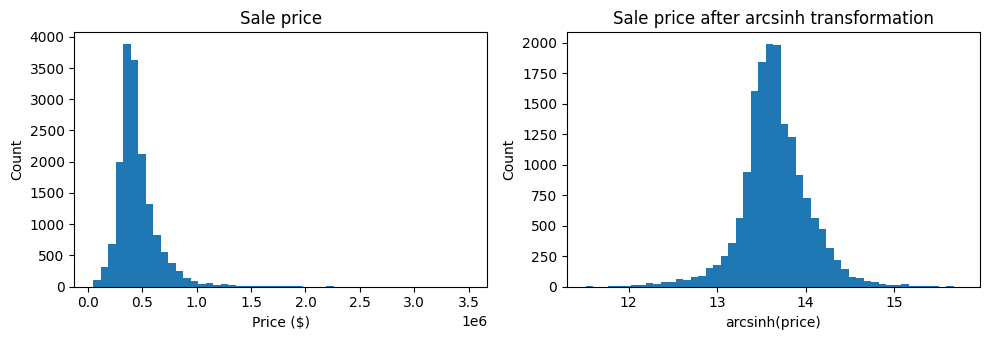

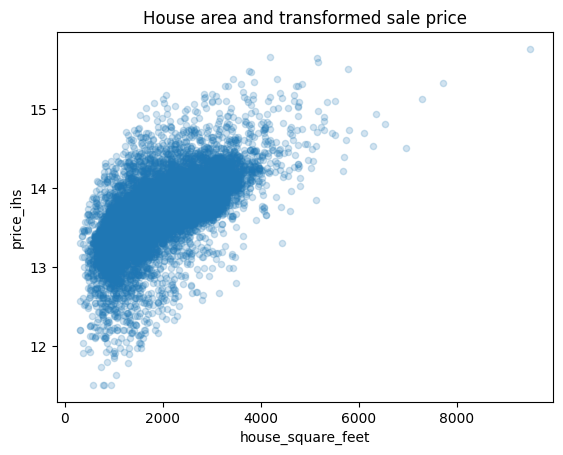

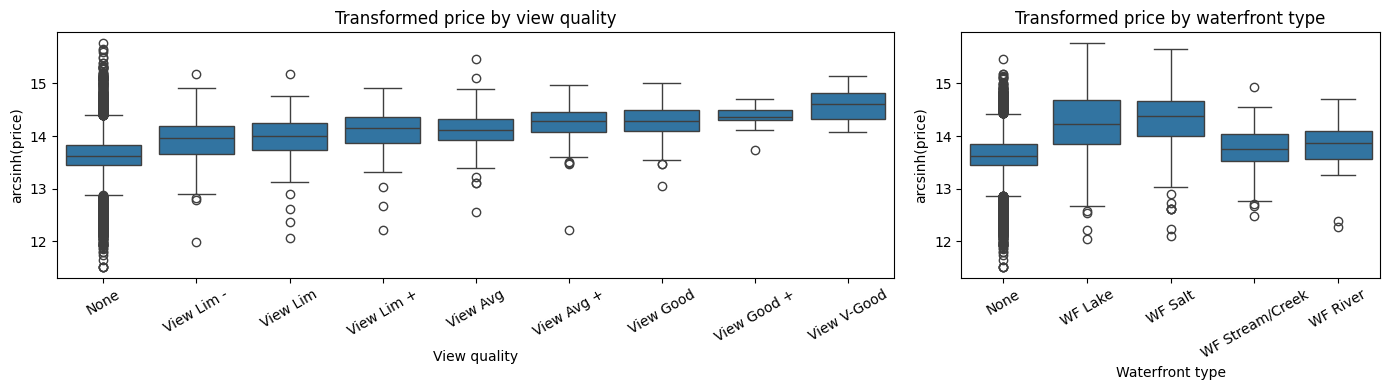

house_square_feet              0.648
bathrooms                      0.547
attached_garage_square_feet    0.413
fireplaces                     0.406
year_built                     0.352
bedrooms                       0.348
stories                        0.274
basement_square_feet           0.258
detached_garage_square_feet    0.026
attic_finished_square_feet    -0.025
Name: price_ihs, dtype: float64 

EDA takeaways:
- Sale price is right skewed (skewness 3.11); after arcsinh the skewness is -0.10, so we model arcsinh(price).
- House area has the strongest correlation with price (0.648), followed by bathrooms (0.547).
- Only 3.0% of houses are waterfront and 5.4% have a view, but both sell for clearly more: the median salt-water house sells for $875,000 vs $415,000 for non-waterfront.
- Attic and detached garage area are zero for 93% and 94% of houses, so their correlations with price are weak.


In [32]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.metrics import root_mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures, StandardScaler

df = pd.read_csv("pierce_county_house_sales.csv")

#1 Clean the data pierce_county_house_sales.csv and perform some EDA and visualization to get to know the data set.
# Look at initial characteristics
print("df.shape:")
print(df.shape, '\n')
print("df.dtypes:")
print(df.dtypes, '\n')
display(df.describe())
print(df.isnull().sum(), '\n')

# Look at the categorical variables
for var in ["hvac_description", "exterior", "interior", "roof_cover", "waterfront_type", "view_quality", "utility_sewer"]:
    print(df[var].value_counts(dropna=False), '\n')

# Clean the data
n_start = len(df)
df = df.drop_duplicates()
n_duplicates = n_start - len(df)
df["waterfront_type"] = df["waterfront_type"].fillna("None")
df["view_quality"] = df["view_quality"].fillna("None")
df["hvac_description"] = df["hvac_description"].replace("Floor Wall Furnace", "Floor/Wall Furnace")

# interior and utility_sewer are almost constant, so they can't explain price differences
drywall_share = (df["interior"] == "Drywall").mean()
sewer_share = (df["utility_sewer"] == "SEWER/SEPTIC INSTALLED").mean()
df = df.drop(columns=["interior", "utility_sewer", "sale_date"])

n_before_na = len(df)
df = df.dropna(subset=["hvac_description", "exterior", "roof_cover"])
n_missing = n_before_na - len(df)

# transform price
df["price_ihs"] = np.arcsinh(df["sale_price"])

# Trim recording errors and non-market sales
# Price per square foot catches bad sales the other filters miss, like a 480 sq ft house sold for $6.13M
ppsf = df["sale_price"] / df["house_square_feet"]
keep = (df["price_ihs"] > 11.5) & (df["house_square_feet"] >= 300) & (df["bedrooms"] <= 10) & ppsf.between(50, 1000)
n_trimmed = (~keep).sum()
df = df.loc[keep].copy()

print(f"Removed {n_duplicates} duplicate rows, {n_missing} rows missing hvac/exterior/roof, and {n_trimmed} non-market or error sales.")
print(f"Kept {len(df)} of {n_start} rows ({len(df) / n_start:.1%}).")
print(f"Dropped interior ({drywall_share:.1%} Drywall) and utility_sewer ({sewer_share:.1%} installed) because they are almost constant.")
print(f"Price cutoff: arcsinh(price) > 11.5 means price > ${np.sinh(11.5):,.0f}. Price per sq ft is kept between $50 and $1,000.")

# Plot price before and after the arcsinh transformation
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
df["sale_price"].hist(bins=50, grid=False, ax=axes[0])
axes[0].set(title="Sale price", xlabel="Price ($)", ylabel="Count")
df["price_ihs"].hist(bins=50, grid=False, ax=axes[1])
axes[1].set(title="Sale price after arcsinh transformation", xlabel="arcsinh(price)", ylabel="Count")
plt.tight_layout()
plt.show()

# Plot house area against transformed price
df.plot.scatter(x="house_square_feet", y="price_ihs", alpha=0.2)
plt.title("House area and transformed sale price")
plt.show()

# Plot transformed price by view and waterfront
view_order = ["None", "View Lim -", "View Lim", "View Lim +", "View Avg", "View Avg +", "View Good", "View Good +", "View V-Good"]
view_order = [v for v in view_order if v in df["view_quality"].unique()]
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2, 1]})
sns.boxplot(data=df, x="view_quality", y="price_ihs", order=view_order, ax=axes[0])
axes[0].set(title="Transformed price by view quality", xlabel="View quality", ylabel="arcsinh(price)")
axes[0].tick_params(axis="x", rotation=30)
sns.boxplot(data=df, x="waterfront_type", y="price_ihs", ax=axes[1])
axes[1].set(title="Transformed price by waterfront type", xlabel="Waterfront type", ylabel="arcsinh(price)")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

# Correlate numeric variables with transformed price
numeric_vars = ["house_square_feet", "attic_finished_square_feet", "basement_square_feet", "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces", "stories", "bedrooms", "bathrooms", "year_built"]
correlations = df[numeric_vars + ["price_ihs"]].corr()["price_ihs"].drop("price_ihs").sort_values(ascending=False)
print(correlations.round(3), '\n')

# EDA takeaways, computed from the data
median_price = df.groupby("waterfront_type")["sale_price"].median()
waterfront_share = (df["waterfront_type"] != "None").mean()
view_share = (df["view_quality"] != "None").mean()
zero_share = (df[numeric_vars] == 0).mean()
print("EDA takeaways:")
print(f"- Sale price is right skewed (skewness {df['sale_price'].skew():.2f}); after arcsinh the skewness is {df['price_ihs'].skew():.2f}, so we model arcsinh(price).")
print(f"- House area has the strongest correlation with price ({correlations.iloc[0]:.3f}), followed by {correlations.index[1]} ({correlations.iloc[1]:.3f}).")
print(f"- Only {waterfront_share:.1%} of houses are waterfront and {view_share:.1%} have a view, but both sell for clearly more: "
      f"the median salt-water house sells for ${median_price['WF Salt']:,.0f} vs ${median_price['None']:,.0f} for non-waterfront.")
print(f"- Attic and detached garage area are zero for {zero_share['attic_finished_square_feet']:.0%} and {zero_share['detached_garage_square_feet']:.0%} of houses, so their correlations with price are weak.")

# %%

In [33]:
# %%
#2 Transform your variables - particularly categorical ones - for use in your regression analysis.

# Group exterior types with fewer than 15 houses into "Other" so no dummy is (almost) all zeros
exterior_counts = df["exterior"].value_counts()
rare_exteriors = exterior_counts[exterior_counts < 15].index
df["exterior"] = df["exterior"].replace(rare_exteriors, "Other")
print("Exterior types grouped into Other:", list(rare_exteriors), '\n')

# drop_first=True leaves one level of each variable out as the baseline, which avoids perfect collinearity (the dummy variable trap)
categorical_vars = ["hvac_description", "exterior", "roof_cover", "waterfront_type", "view_quality"]
dummies = pd.get_dummies(df[categorical_vars], drop_first=True, dtype=int)
print(f"{dummies.shape[1]} dummy columns:", dummies.columns.tolist())

# Combine numeric variables and dummies into X, with transformed price as y
X = pd.concat([df[numeric_vars], dummies], axis=1)
y = df["price_ihs"]

# %%

Exterior types grouped into Other: ['Frame Hardboard', 'Log', 'Cedar A-Frame', 'Cedar Finished Cabin', 'Pine A-Frame', 'Pine Finished Cabin', 'Unfinished Cottage', 'Cedar Unfinished Cabin', 'Pine Unfinished Cabin'] 

31 dummy columns: ['hvac_description_Electric Baseboard', 'hvac_description_Floor/Wall Furnace', 'hvac_description_Forced Air', 'hvac_description_Heat Pump', 'hvac_description_Hot Water Baseboard', 'hvac_description_No Heat', 'hvac_description_Warm and Cool Air Zone', 'exterior_Frame Rustic Log', 'exterior_Frame Siding', 'exterior_Frame Stucco', 'exterior_Frame Vinyl', 'exterior_Masonry Common Brick', 'exterior_Masonry Concrete Block', 'exterior_Other', 'roof_cover_Composition Shingle', 'roof_cover_Concrete Tile', 'roof_cover_Formed Seam Metal', 'roof_cover_Preformed Metal', 'roof_cover_Wood Shake', 'waterfront_type_WF Lake', 'waterfront_type_WF River', 'waterfront_type_WF Salt', 'waterfront_type_WF Stream/Creek', 'view_quality_View Avg', 'view_quality_View Avg +', 'view_q

In [34]:
# %%
#3 Implement an 80/20 train-test split. Put the test data aside.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=55
)
print(f"Training rows: {len(X_train)}, test rows: {len(X_test)} ({len(X_test) / len(X):.0%} held out)")
print("Smallest number of training houses in any dummy:", X_train[dummies.columns].sum().min())

# %%

Training rows: 13282, test rows: 3321 (20% held out)
Smallest number of training houses in any dummy: 12


In [35]:
# 4 Build some simple linear models that include no transformations or interactions.
# Fit them, and determine their RMSE and R2 on the both the training and test sets. Which of your models does the best?

results = {}

def evaluate(name, model, X_tr, X_te):
    """Store and print training and test R-squared, RMSE and median absolute error."""
    train_prediction = model.predict(X_tr)
    test_prediction = model.predict(X_te)
    results[name] = {
        "Train R2": model.score(X_tr, y_train),
        "Test R2": model.score(X_te, y_test),
        "Train RMSE": root_mean_squared_error(y_train, train_prediction),
        "Test RMSE": root_mean_squared_error(y_test, test_prediction),
        "Test median abs error": np.median(np.abs(y_test - test_prediction)),
    }
    r = results[name]
    print(name)
    print("Training R-squared:", round(r["Train R2"], 3))
    print("Test R-squared:", round(r["Test R2"], 3))
    print("Training RMSE:", round(r["Train RMSE"], 3))
    print("Test RMSE:", round(r["Test RMSE"], 3))
    print("-------------------")

model_sets = {
    "House area only": ["house_square_feet"],
    "Numeric features": numeric_vars,
    "All features": X_train.columns.tolist(),
}

for name, features in model_sets.items():
    sk_fit = LinearRegression().fit(X_train[features], y_train)
    evaluate(name, sk_fit, X_train[features], X_test[features])

simple = pd.DataFrame(results).T.loc[list(model_sets)]
best = simple["Test R2"].idxmax()
print(f"The '{best}' model does best, with the highest test R-squared ({simple.loc[best, 'Test R2']:.3f}) and the lowest test RMSE ({simple.loc[best, 'Test RMSE']:.3f}).")
print(f"Every increase in features helped. House area alone had a test R-squared of {simple.loc['House area only', 'Test R2']:.3f}, "
      f"adding the other numeric features raised it to {simple.loc['Numeric features', 'Test R2']:.3f}, "
      f"and adding the categorical dummies on top raised it to {simple.loc['All features', 'Test R2']:.3f}.")
gap = (simple["Train R2"] - simple["Test R2"]).abs().max()
print(f"The training and test R-squared differ by at most {gap:.3f} for every model, so none are overfitting.")

# %%

House area only
Training R-squared: 0.423
Test R-squared: 0.407
Training RMSE: 0.295
Test RMSE: 0.296
-------------------
Numeric features
Training R-squared: 0.528
Test R-squared: 0.506
Training RMSE: 0.267
Test RMSE: 0.27
-------------------
All features
Training R-squared: 0.579
Test R-squared: 0.55
Training RMSE: 0.252
Test RMSE: 0.258
-------------------
The 'All features' model does best, with the highest test R-squared (0.550) and the lowest test RMSE (0.258).
Every increase in features helped. House area alone had a test R-squared of 0.407, adding the other numeric features raised it to 0.506, and adding the categorical dummies on top raised it to 0.550.
The training and test R-squared differ by at most 0.029 for every model, so none are overfitting.


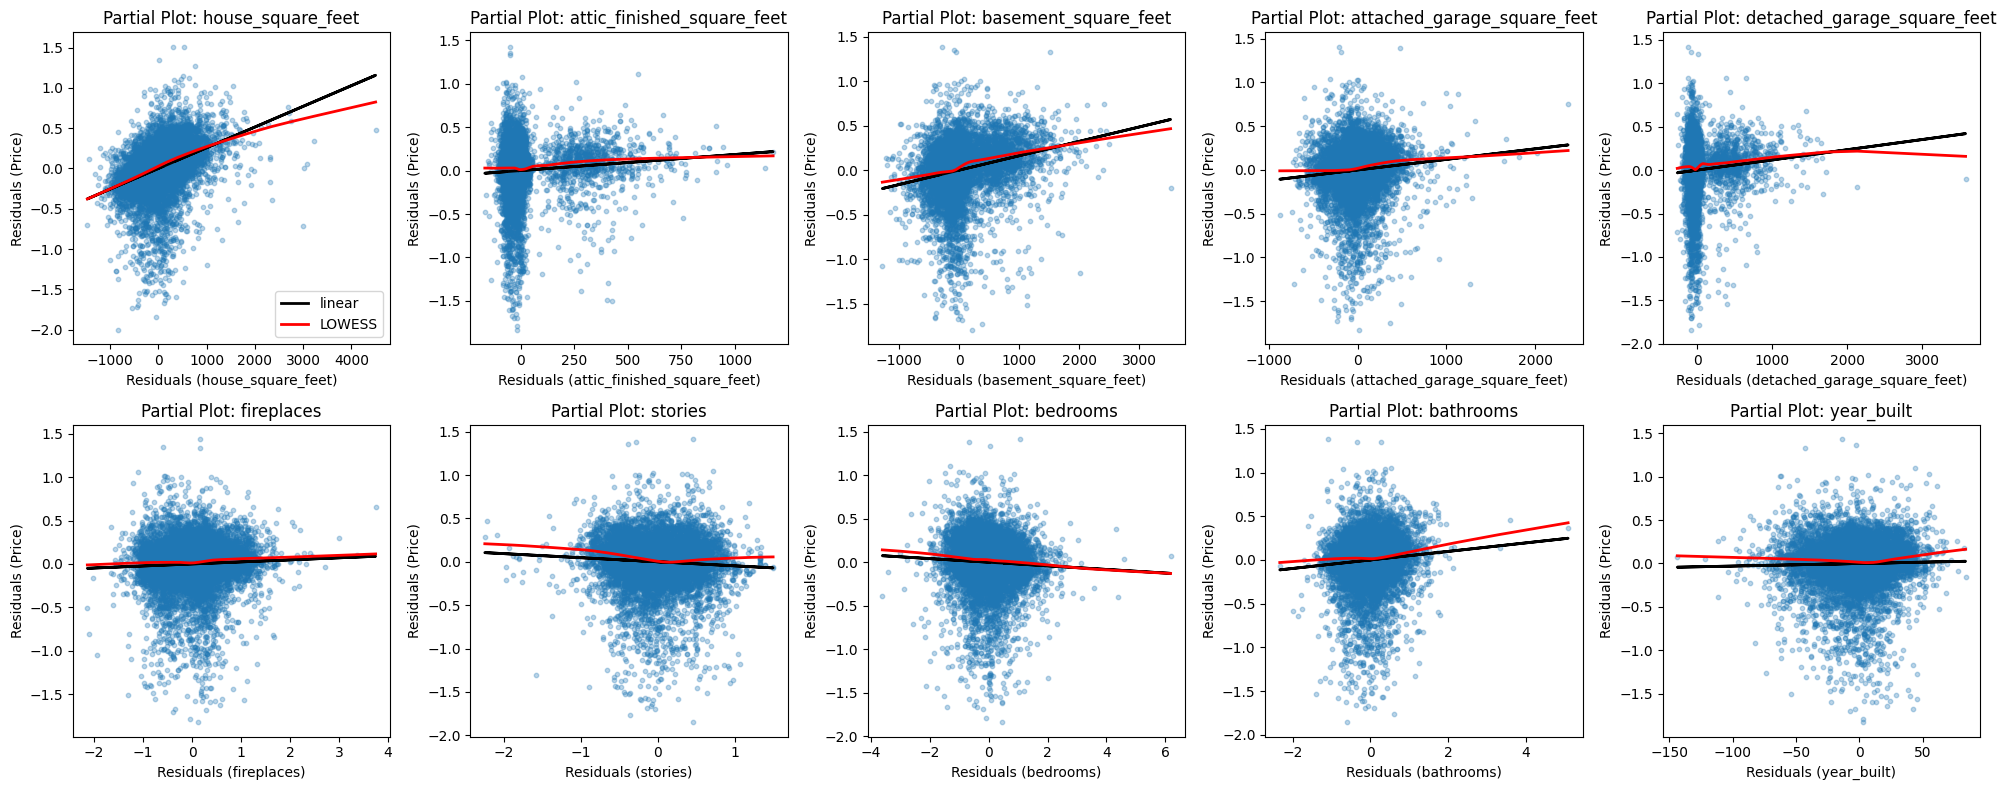

                             unit  % change in price per unit  squared-term t
feature                                                                      
house_square_feet             100                        2.57          -12.23
attic_finished_square_feet    100                        1.84           -0.98
basement_square_feet          100                        1.62           -8.38
attached_garage_square_feet   100                        1.20            1.64
detached_garage_square_feet   100                        1.17           -2.11
fireplaces                      1                        2.35            0.99
stories                         1                       -4.69           -1.11
bedrooms                        1                       -2.07           -5.50
bathrooms                       1                        4.86           -9.47
year_built                     10                        0.30            8.78 

Because arcsinh(price) is close to log(price), each slope time

In [36]:
#5 Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
def slr(x, y):
    """Fit an intercept and one slope by ordinary least squares."""
    x_bar, y_bar = np.mean(x), np.mean(y)
    b1 = np.inner(x - x_bar, y - y_bar) / np.inner(x - x_bar, x - x_bar)
    b0 = y_bar - b1 * x_bar
    y_hat = b0 + b1 * x
    return {"b0": b0, "b1": b1, "y_hat": y_hat, "residuals": y - y_hat}

numeric_features = numeric_vars
X_train_float = X_train.astype(float)

# Unit for reporting each slope: per 100 sq ft for areas, per 10 years for year_built, per 1 for counts
units = {f: 100 for f in numeric_features if "square_feet" in f}
units.update({"year_built": 10, "fireplaces": 1, "stories": 1, "bedrooms": 1, "bathrooms": 1})

fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(20, 8))
axes = axes.flatten()
summary = []

for i, feature in enumerate(numeric_features):
    others = X_train.drop(columns=feature)
    r_price = y_train - LinearRegression().fit(others, y_train).predict(others)
    r_feature = X_train[feature] - LinearRegression().fit(others, X_train[feature]).predict(others)
    partial_fit = slr(r_feature, r_price)

    # Curvature test: add a centered squared term to the all-features model and look at its t-statistic
    X_sq = X_train_float.copy()
    X_sq["squared"] = (X_train[feature] - X_train[feature].mean()) ** 2
    t_squared = sm.OLS(y_train, sm.add_constant(X_sq)).fit().tvalues["squared"]
    summary.append({
        "feature": feature,
        "unit": units[feature],
        "% change in price per unit": 100 * partial_fit["b1"] * units[feature],
        "squared-term t": t_squared,
    })

    ax = axes[i]
    ax.scatter(r_feature, r_price, alpha=0.3, s=10)
    ax.plot(r_feature, partial_fit["y_hat"], color="black", linewidth=2, label="linear")
    smooth = sm.nonparametric.lowess(r_price, r_feature)
    ax.plot(smooth[:, 0], smooth[:, 1], color="red", linewidth=2, label="LOWESS")
    ax.set_title(f"Partial Plot: {feature}")
    ax.set_xlabel(f"Residuals ({feature})")
    ax.set_ylabel("Residuals (Price)")
axes[0].legend()

plt.tight_layout()
plt.show()

summary = pd.DataFrame(summary).set_index("feature")
print(summary.round(2), '\n')

t = summary["squared-term t"]
print("Because arcsinh(price) is close to log(price), each slope times 100 is roughly the % change in price per unit.")
print(f"With {len(X_train)} training rows every slope is statistically significant, so the effect sizes matter more than p-values. "
      f"For example, 100 more sq ft of house adds about {summary.loc['house_square_feet', '% change in price per unit']:.1f}% to the price, "
      f"and one more bathroom adds about {summary.loc['bathrooms', '% change in price per unit']:.1f}%.")
print(f"House area is the clearest non-linearity: the LOWESS curve flattens for the biggest houses, so each extra square foot adds less (squared-term t = {t['house_square_feet']:.1f}). Basement area bends the same way (t = {t['basement_square_feet']:.1f}).")
print(f"year_built is U-shaped (squared-term t = {t['year_built']:.1f}): the LOWESS curve rises above the straight line for the newest homes and sits slightly above it for the oldest ones.")
print(f"Bathrooms has a significant squared term (t = {t['bathrooms']:.1f}), but the few houses with the most bathrooms pull the LOWESS curve up, so the plot itself shows no clear bend.")
print(f"Bedrooms has a negative effect ({summary.loc['bedrooms', '% change in price per unit']:.1f}% per bedroom) once size is held fixed, because more bedrooms in the same space means smaller rooms.")
print("Attic and detached garage area are zero for most houses, so their plots are mostly a vertical stripe at zero and a straight line describes them poorly.")

# %%

In [37]:
#6 Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value.
# Determine its RMSE and R2 on the training and test sets. How does the more complex model your build compare to the simpler ones?

# Log-transform house size
X_train_log = X_train.copy()
X_test_log = X_test.copy()
X_train_log["house_square_feet"] = np.log(X_train_log["house_square_feet"])
X_test_log["house_square_feet"] = np.log(X_test_log["house_square_feet"])

# Add squares and interactions of the numeric features
expander = make_pipeline(
    MinMaxScaler(feature_range=(-1, 1)),
    PolynomialFeatures(degree=2, include_bias=False)
)
poly_train = pd.DataFrame(expander.fit_transform(X_train_log[numeric_features]), columns=expander.get_feature_names_out(), index=X_train_log.index)
poly_test = pd.DataFrame(expander.transform(X_test_log[numeric_features]), columns=expander.get_feature_names_out(), index=X_test_log.index)

# Combine with the dummies and fit the complex model
X_train_c = pd.concat([poly_train, X_train_log.drop(columns=numeric_features)], axis=1)
X_test_c = pd.concat([poly_test, X_test_log.drop(columns=numeric_features)], axis=1)
c_model = LinearRegression().fit(X_train_c, y_train)
evaluate("Complex", c_model, X_train_c, X_test_c)

# Check: does the log of house area help on its own, without squares or interactions?
log_only = LinearRegression().fit(X_train_log, y_train)
log_only_test_r2 = log_only.score(X_test_log, y_test)

# Correlations that motivate the interactions
feature_corr = df[numeric_features].corr()
c_coef = pd.Series(c_model.coef_, index=X_train_c.columns)

complex_r = results["Complex"]
all_r = results["All features"]
year_sq = c_coef["year_built^2"]
area_bath = c_coef["house_square_feet bathrooms"]
print("Why these terms: the partial plots showed diminishing returns to house area and a U-shape for year_built, so we log-transformed house area and added squared terms. "
      f"The fitted year_built^2 coefficient is {year_sq:+.3f}, which {'confirms' if year_sq > 0 else 'does not confirm'} the U-shape (a positive value means old and new homes both sell for more).")
print(f"Interactions let one feature change another's effect. House area is strongly correlated with bathrooms ({feature_corr.loc['house_square_feet', 'bathrooms']:.2f}) "
      f"and bedrooms ({feature_corr.loc['house_square_feet', 'bedrooms']:.2f}), so an extra bathroom or bedroom means something different in a large house than in a small one. "
      f"The house area x bathrooms coefficient is {area_bath:+.3f}, so an extra bathroom adds {'less' if area_bath < 0 else 'more'} value in a bigger house.")
print(f"Taking the log of house area alone gives a test R-squared of {log_only_test_r2:.3f} vs {all_r['Test R2']:.3f} for the all-features model, so most of the gain comes from the squares and interactions, not the log.")
print(f"The complex model beats every simple model on the test set: test R-squared {complex_r['Test R2']:.3f} vs {all_r['Test R2']:.3f}, and test RMSE {complex_r['Test RMSE']:.3f} vs {all_r['Test RMSE']:.3f}.")
print(f"Its training and test R-squared are close ({complex_r['Train R2']:.3f} vs {complex_r['Test R2']:.3f}), so it isn't overfitting.")

# %%

Complex
Training R-squared: 0.601
Test R-squared: 0.569
Training RMSE: 0.245
Test RMSE: 0.252
-------------------
Why these terms: the partial plots showed diminishing returns to house area and a U-shape for year_built, so we log-transformed house area and added squared terms. The fitted year_built^2 coefficient is +0.081, which confirms the U-shape (a positive value means old and new homes both sell for more).
Interactions let one feature change another's effect. House area is strongly correlated with bathrooms (0.74) and bedrooms (0.59), so an extra bathroom or bedroom means something different in a large house than in a small one. The house area x bathrooms coefficient is -0.078, so an extra bathroom adds less value in a bigger house.
Taking the log of house area alone gives a test R-squared of 0.552 vs 0.550 for the all-features model, so most of the gain comes from the squares and interactions, not the log.
The complex model beats every simple model on the test set: test R-squared

In [38]:
# 7 Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
summary_table = pd.DataFrame(results).T
display(summary_table.round(3))

area_r, complex_r = results["House area only"], results["Complex"]
print(f"After cleaning (removing duplicates, filling missing waterfront and view values, dropping near-constant columns, and trimming {n_trimmed} non-market or error sales), "
      f"we transformed sale price with arcsinh, encoded the categorical variables as dummies, and used an 80/20 train-test split.")
print("EDA showed that price is right skewed, that house area is the strongest single predictor, and that waterfront and view homes sell for much more.")
for name, r in results.items():
    print(f"{name}: training R^2 {r['Train R2']:.3f}, test R^2 {r['Test R2']:.3f}, training RMSE {r['Train RMSE']:.3f}, test RMSE {r['Test RMSE']:.3f}.")

print(f"RMSE is on the arcsinh price scale, which is close to log(price). The complex model's median test error is {complex_r['Test median abs error']:.3f}, "
      f"so a typical prediction is off by about {np.exp(complex_r['Test median abs error']) - 1:.0%} of the sale price. "
      f"RMSE ({complex_r['Test RMSE']:.3f}) is larger because squaring gives a few badly predicted sales a lot of weight.")
print(f"The house area model underfits: it is too simple to capture what drives price, so its training and test errors are both high (test RMSE {area_r['Test RMSE']:.3f}). "
      "Adding the other numeric features and the categorical dummies lowered the error on both sets.")
print(f"The all-features simple model explains roughly {results['All features']['Test R2']:.0%} of the variation in price on unseen data, with a small gap between training and test, so it is not overfitting.")
print("The complex model did better than every simple model on the test set, and its training and test metrics stayed close, so the extra terms captured real patterns instead of noise.")
print("We learned that test metrics are what tell us whether a model is overfitting. Training error always goes down as we add features, so only the test set shows whether a model is actually learning or just memorizing the training data.")
print("We also learned that model selection is about finding a good in-between. We needed a model complex enough to capture patterns like the U-shape in year_built and diminishing returns to house size, "
      "but we limited the squares and interactions to the numeric features instead of every column to avoid overfitting.")

# %%

,Train R2,Test R2,Train RMSE,Test RMSE,Test median abs error
House area only,0.423,0.407,0.295,0.296,0.135
Numeric features,0.528,0.506,0.267,0.270,0.121
All features,0.579,0.550,0.252,0.258,0.119
Complex,0.601,0.569,0.245,0.252,0.118


After cleaning (removing duplicates, filling missing waterfront and view values, dropping near-constant columns, and trimming 152 non-market or error sales), we transformed sale price with arcsinh, encoded the categorical variables as dummies, and used an 80/20 train-test split.
EDA showed that price is right skewed, that house area is the strongest single predictor, and that waterfront and view homes sell for much more.
House area only: training R^2 0.423, test R^2 0.407, training RMSE 0.295, test RMSE 0.296.
Numeric features: training R^2 0.528, test R^2 0.506, training RMSE 0.267, test RMSE 0.270.
All features: training R^2 0.579, test R^2 0.550, training RMSE 0.252, test RMSE 0.258.
Complex: training R^2 0.601, test R^2 0.569, training RMSE 0.245, test RMSE 0.252.
RMSE is on the arcsinh price scale, which is close to log(price). The complex model's median test error is 0.118, so a typical prediction is off by about 12% of the sale price. RMSE (0.252) is larger because squaring give

In [39]:
#8 Use the sklearn.linear_model.Lasso to regularize your model and select the most predictive features.
# Which does it select? What are the RMSE and R2?

# Standardize the complex-model features then fit the lasso
model = make_pipeline(StandardScaler(), Lasso(max_iter=20000))

# Choose the penalty by 5-fold cross-validation on the training data
cv = KFold(n_splits=5, shuffle=True, random_state=3001)
alphas = [0.00003, 0.0001, 0.0003, 0.001, 0.003, 0.01]
search = GridSearchCV(model, {"lasso__alpha": alphas}, cv=cv, scoring="neg_root_mean_squared_error", error_score="raise")
search.fit(X_train_c, y_train);
best_alpha = search.best_params_["lasso__alpha"]
print("Selected alpha:", best_alpha, "(at the edge of the grid; widen it)" if best_alpha in (alphas[0], alphas[-1]) else "(inside the grid)")
print("Validation RMSE:", round(-search.best_score_, 3))

# Training and test R-squared and RMSE of the refitted model
best_model = search.best_estimator_
evaluate("Lasso", best_model, X_train_c, X_test_c)

# Features with nonzero coefficients
lasso = best_model.named_steps["lasso"]
coefs = pd.Series(lasso.coef_, index=X_train_c.columns)
selected = coefs[coefs != 0]
selected = selected.reindex(selected.abs().sort_values(ascending=False).index)
print("Nonzero coefficients:", len(selected), "of", len(coefs))
print("15 largest coefficients (standardized features):")
print(selected.head(15).round(3).to_string())
print("")

lasso_r, complex_r = results["Lasso"], results["Complex"]
print(f"Cross-validation picked alpha = {best_alpha}. The lasso's test R-squared is {lasso_r['Test R2']:.3f} and test RMSE is {lasso_r['Test RMSE']:.3f}.")
print(f"It keeps {len(selected)} of the {len(coefs)} features. The five most important are: {', '.join(selected.index[:5])}.")
print(f"It does about as well as the complex model (test R-squared {lasso_r['Test R2']:.3f} vs {complex_r['Test R2']:.3f}) while using {len(coefs) - len(selected)} fewer features.")

Selected alpha: 0.0003 (inside the grid)
Validation RMSE: 0.248
Lasso
Training R-squared: 0.599
Test R-squared: 0.57
Training RMSE: 0.246
Test RMSE: 0.252
-------------------
Nonzero coefficients: 72 of 96
15 largest coefficients (standardized features):
house_square_feet                         0.149
bathrooms                                 0.089
basement_square_feet^2                   -0.061
basement_square_feet year_built           0.057
waterfront_type_WF Salt                   0.055
bathrooms year_built                     -0.054
house_square_feet year_built              0.048
waterfront_type_WF Lake                   0.045
house_square_feet basement_square_feet   -0.038
fireplaces year_built                    -0.035
basement_square_feet bathrooms            0.033
house_square_feet fireplaces              0.030
stories year_built                       -0.029
year_built^2                              0.027
attached_garage_square_feet year_built    0.027

Cross-validation picked 

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The main improvements were better cleaning and clearer explanations for each of the questions. The price-per-square-foot filter ai suggested ended up removing 152 bad sales that the filters in the original code missed. Rare exterior types were grouped into “Other.” The partial plots now show a curved trend line, and the code calculates every number that's reported in the print statements answering the questions instead of having it hardtyped in. Additionally, the complex model’s test R^2 went from 0.543 to 0.569, which signals an improvement in the model.

However, the AI still made a couple mistakes like suggesting reporting p-values, but they were all about 0 with this much data and suggesting Q6 changes that didn’t help when tested. It said that bathrooms have diminishing returns, but the plot didn’t show that. The first Lasso search range suggested by it was also too narrow.

To check the work, we checked to see if the new numbers matched the original numbers (if they should), then we ran the full notebook from start to finish. We compared every claim to the results and plots.

Some remaining concerns are how the 50 dollar and 1,000 dollar cutoffs for cleaning data are subjective, and changing them would change a lot of results from the assignment. Additionally, all results come from a single train-test split, and reading the slopes as percent changes is only approximate and not exact, so results could be a bit off.